# Logistic Regression for Multiclass classification

<b>Logistic Regression model</b>  is used to model the probability of a certain class or event existing such as pass/fail, win/lose, alive/dead or healthy/sick.

A <b>binary logistic model</b> has a dependent variable with two possible values, such as pass/fail which is represented by labels 1/0.

<div align="right">   Reference: Wikipedia </div>

The same <b>Logistic Classifier</b> can be applied for multinomial classification also.

## 1. Import necessary libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

## 2. Import and preprocess the dataset

Iris dataset consists of 150 observations.

The features or attributed (columns) are Sepal Length, Sepal Width, Petal Length and Petal Width.

The observations (rows) belong to 3 different types of iris species - Setosa, Versicolour, and Virginica. Each class has 50 observations.

The iris dataset can be downloded from Kaggle: https://www.kaggle.com/uciml/iris as csv file.


In [2]:
# Load Iris dataset.

iris = load_iris()
iris.data.shape



(150, 4)

In [3]:
# Extract two columns from the dataset for X values.
# X is  petal length, petal width.
# y is the target column.

X = iris["data"][:,(2,3)]
y = iris["target"]
unique, count = np.unique(y, return_counts = True)
print(unique,count)

[0 1 2] [50 50 50]


In [4]:
X.shape

(150, 2)

In [5]:
# Split data into train and test

(X_train, X_test, y_train, y_test) = train_test_split(X, y, stratify=y, test_size= 0.3, random_state=42)


## 3. Create and train the machine learning model

In [6]:
# build the model
# With the default lbfgs solver, LogisticRegression on >2 classes already fits the
# multinomial (softmax) model; C is the inverse regularisation strength.
logreg = LogisticRegression(solver="lbfgs", C=5, max_iter=200)
logreg.fit(X_train,y_train) # train

LogisticRegression(C=5, max_iter=200)

## 4. Make Predictions

In [7]:
# predict the values

y_pred  = logreg.predict(X_test)


## 5. Performance measures

In [8]:
acc = accuracy_score(y_test, y_pred)
print(acc * 100)

93.33333333333333


In [9]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, y_pred)
print('Confusion Matrix :')
print(conf_matrix)


Confusion Matrix :
[[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]


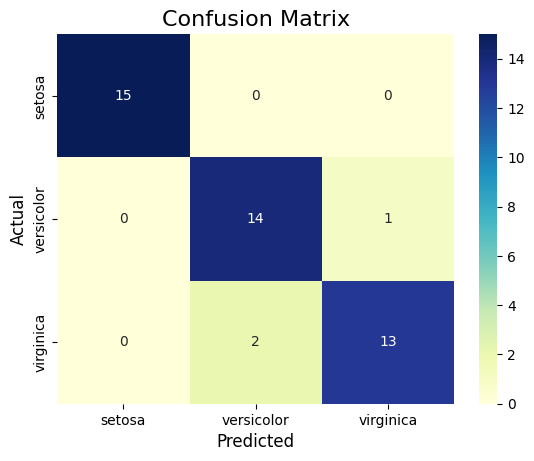

In [10]:
import seaborn as sns
# Plot the confusion matrix
sns.heatmap(conf_matrix, annot=True,fmt='d', cmap='YlGnBu', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.ylabel('Actual',fontsize=12)
plt.xlabel('Predicted',fontsize=12)
plt.title('Confusion Matrix',fontsize=16)
plt.show()

In [11]:
from sklearn.metrics import classification_report

print('Classification Report:')
print(classification_report(y_test, y_pred))
# support: number of TRUE samples of each class in y_test (the denominator of recall)

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.88      0.93      0.90        15
           2       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.93      0.93        45
weighted avg       0.93      0.93      0.93        45



 macro-averaged F1 score ( is computed by taking the arithmetic mean  of all the per-class F1 scores. This method treats all classes equally regardless of their support values.

 weighted-averaged F1 score is calculated by taking the mean of all per-class F1 scores while considering each class’s support proportion

In imbalanced dataset and aiming to give more weight to classes with larger examples, weighted average is preferable.

 In imbalanced dataset where equal importance is attributed to all classes, opting for the macro average


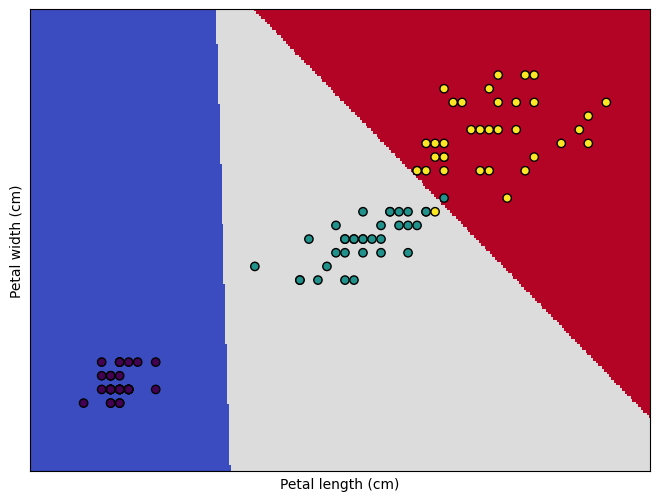

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Plot the decision boundary. For that, we will assign a color to each
# point in the mesh [x_min, x_max]x[y_min, y_max].
x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5

h = 0.02  # step size in the mesh

xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = logreg.predict(np.c_[xx.ravel(), yy.ravel()])

# Put the result into a color plot
Z = Z.reshape(xx.shape)

plt.figure(1, figsize=(8,6))
plt.pcolormesh(xx, yy, Z, cmap=plt.cm.coolwarm)

# Plot also the training points
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolors='k', cmap=plt.cm.viridis)

plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')

plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xticks(())
plt.yticks(())

plt.show()